In [1]:
%cd "C:\Users\touta\OneDrive\Desktop\ADD"

C:\Users\touta\OneDrive\Desktop\ADD


In [2]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [3]:
df=pd.read_csv("exo01.csv")

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Marque  8 non-null      str  
 1   X       8 non-null      int64
 2   Y       8 non-null      int64
 3   Z       8 non-null      int64
 4   Groupe  8 non-null      str  
dtypes: int64(3), str(2)
memory usage: 452.0 bytes


In [6]:
bases = df[df['Groupe']=="initial"].set_index('Marque')[["X","Y","Z"]]
supp = df[df['Groupe']=="supplementaire"].set_index('Marque')[["X","Y","Z"]]

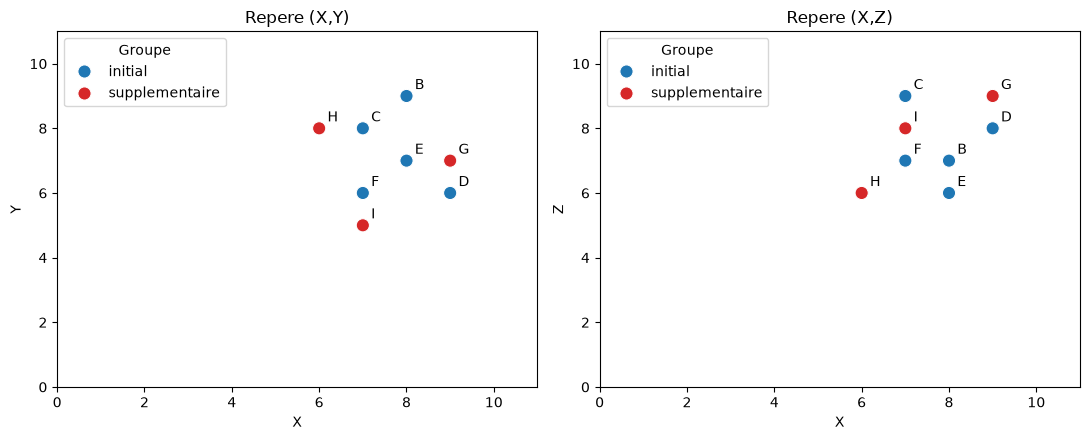

In [7]:
#palette de couleur pour separer les données de base et supp
palette = {"initial": "tab:blue", "supplementaire":"tab:red"}

#1 figure avec 2 panneaux (X,Y) et (Y,Z)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, (a,b) in zip(axes, [("X","Y"), ("X", "Z")]):
    ax.set_ylim(0,11)
    ax.set_xlim(0,11)
    #mettre les points sur le graph et les colorer
    sns.scatterplot(data=df,x=a,y=b, hue="Groupe", palette=palette, s=90,ax=ax)
    #pour chaque marque on met la lettre corresp.
    for _, r in df.iterrows():
        ax.annotate(r["Marque"],(r[a],r[b]),textcoords="offset points", xytext=(6,5))
    #titre du panneau
    ax.set_title(f"Repere ({a},{b})")
plt.tight_layout()
plt.savefig("exo1_scatter.png", dpi=150) #sauvegarder l'image du plot
plt.show() #afficher le plot



In [8]:
#Autres question (2->8)
df_clean=df[df["Groupe"]=="initial"].drop(columns="Groupe") #reinitialisation du dataset
df_clean

,Marque,X,Y,Z
0,B,8,9,7
1,C,7,8,9
2,D,9,6,8
3,E,8,7,6
4,F,7,6,7


In [10]:
moy=df_clean.mean(numeric_only=True)
var=df_clean.var(ddof=1, numeric_only=True) #diviser par n-1 (echantillon)
ecart=df_clean.std(ddof=1,numeric_only=True) #diviser par n-1 (echantillon)
print(f"Moyenne: {moy}\nVariance: {var}\nEcart-Type: {ecart}")

Moyenne: X    7.8
Y    7.2
Z    7.4
dtype: float64
Variance: X    0.7
Y    1.7
Z    1.3
dtype: float64
Ecart-Type: X    0.836660
Y    1.303840
Z    1.140175
dtype: float64


In [11]:
#Matrice Centré Reduite
r_c = df_clean.drop(columns="Marque") - moy #centrer
r_cr = r_c / ecart #réduire
r_cr


,X,Y,Z
0,0.239046,1.380537,-0.350823
1,-0.956183,0.613572,1.403293
2,1.434274,-0.920358,0.526235
3,0.239046,-0.153393,-1.227881
4,-0.956183,-0.920358,-0.350823


<Axes: >

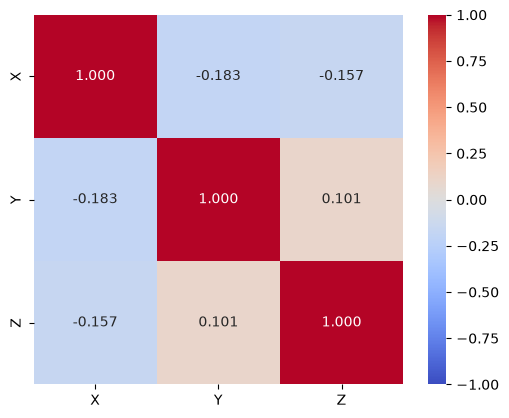

In [12]:
sns.heatmap(df_clean.corr(numeric_only=True), annot=True, fmt=".3f", cmap='coolwarm', vmin=-1, vmax=1, square=True)

In [13]:
#orthogonality (si u1*u2 = 0 donc orthogonal)
u1 = np.array([2,-1,-1])
u2 = np.array([1,1,1])
print(u1 @ u2) #0

0
